# Splatify: Vanilla 3D Gaussian Splatting (3DGS)

Pipeline:
1. ABO images
2. COLMAP camera estimation and sparse points
3. Official vanilla 3DGS training implementation (from scratch, not pretrained)
4. Saved models, profiling results and comparison with inputs for validation.

Camera prep runs on CPU (to conserve GPU hours)
GPU training runs separately using saved preparation outputs. (required loading the COLMAP configuration again)
Reference meshes are not used for training (important to note).

## Load Dataset and Select Images

In [1]:
from pathlib import Path
import csv
import zipfile

# set up the input and output folders
input_root = Path("/kaggle/input")
work_root = Path("/kaggle/working/splatify")
work_root.mkdir(parents=True, exist_ok=True)

# look for the product list in the attached dataset
manifest_paths = list(input_root.rglob("selected_products.csv"))

# extract the dataset if kaggle has kept it inside a zip file
if not manifest_paths:
    dataset_zips = []

    for zip_path in input_root.rglob("*.zip"):
        with zipfile.ZipFile(zip_path) as archive:
            has_manifest = any(
                Path(name).name == "selected_products.csv"
                for name in archive.namelist()
            )

            if has_manifest:
                dataset_zips.append(zip_path)

    if len(dataset_zips) != 1:
        raise RuntimeError(
            f"Expected one ABO dataset ZIP, found {len(dataset_zips)}."
        )

    extract_dir = work_root / "data"
    extract_dir.mkdir(exist_ok=True)

    with zipfile.ZipFile(dataset_zips[0]) as archive:
        # check that every file stays inside the extraction folder
        for entry in archive.infolist():
            target = (extract_dir / entry.filename).resolve()

            if not target.is_relative_to(extract_dir.resolve()):
                raise ValueError(f"Unsafe archive path: {entry.filename}")

        print("Extracting:", dataset_zips[0].name)
        archive.extractall(extract_dir)

    manifest_paths = list(extract_dir.rglob("selected_products.csv"))

if len(manifest_paths) != 1:
    raise RuntimeError(
        f"Expected one product manifest, found {len(manifest_paths)}."
    )

data_root = manifest_paths[0].parent

# read the product metadata
with manifest_paths[0].open(newline="", encoding="utf-8") as file:
    products = list(csv.DictReader(file))

# use all 72 views of the selected chair
product_id = "d3e97083"
num_views = 72

product = next(
    (row for row in products if row["spin_id"] == product_id),
    None,
)

if product is None:
    raise ValueError(f"Product {product_id} was not found.")

if num_views not in [72, 36, 18, 9]:
    raise ValueError("Choose 72, 36, 18, or 9 views.")

view_indices = list(range(0, 72, 72 // num_views))

# build the image paths without loading the reference mesh
image_folder = (
    data_root / "images" / product["product_type"] / product_id
)

image_paths = [
    image_folder / f"{index:02d}.jpg"
    for index in view_indices
]

missing_images = [path for path in image_paths if not path.is_file()]

if missing_images:
    raise FileNotFoundError(
        f"Missing {len(missing_images)} images. First: {missing_images[0]}"
    )

print("Dataset:", data_root)
print("Products:", len(products))
print("Pilot product:", product_id)
print("Category:", product["product_type"])
print("Selected views:", len(image_paths))
print("View indices:", view_indices)

Dataset: /kaggle/input/datasets/chaitanyapeshin/splatify-abo-ablation/abo
Products: 100
Pilot product: d3e97083
Category: CHAIR
Selected views: 72
View indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71]


## Preview Select View Images of the Dataset

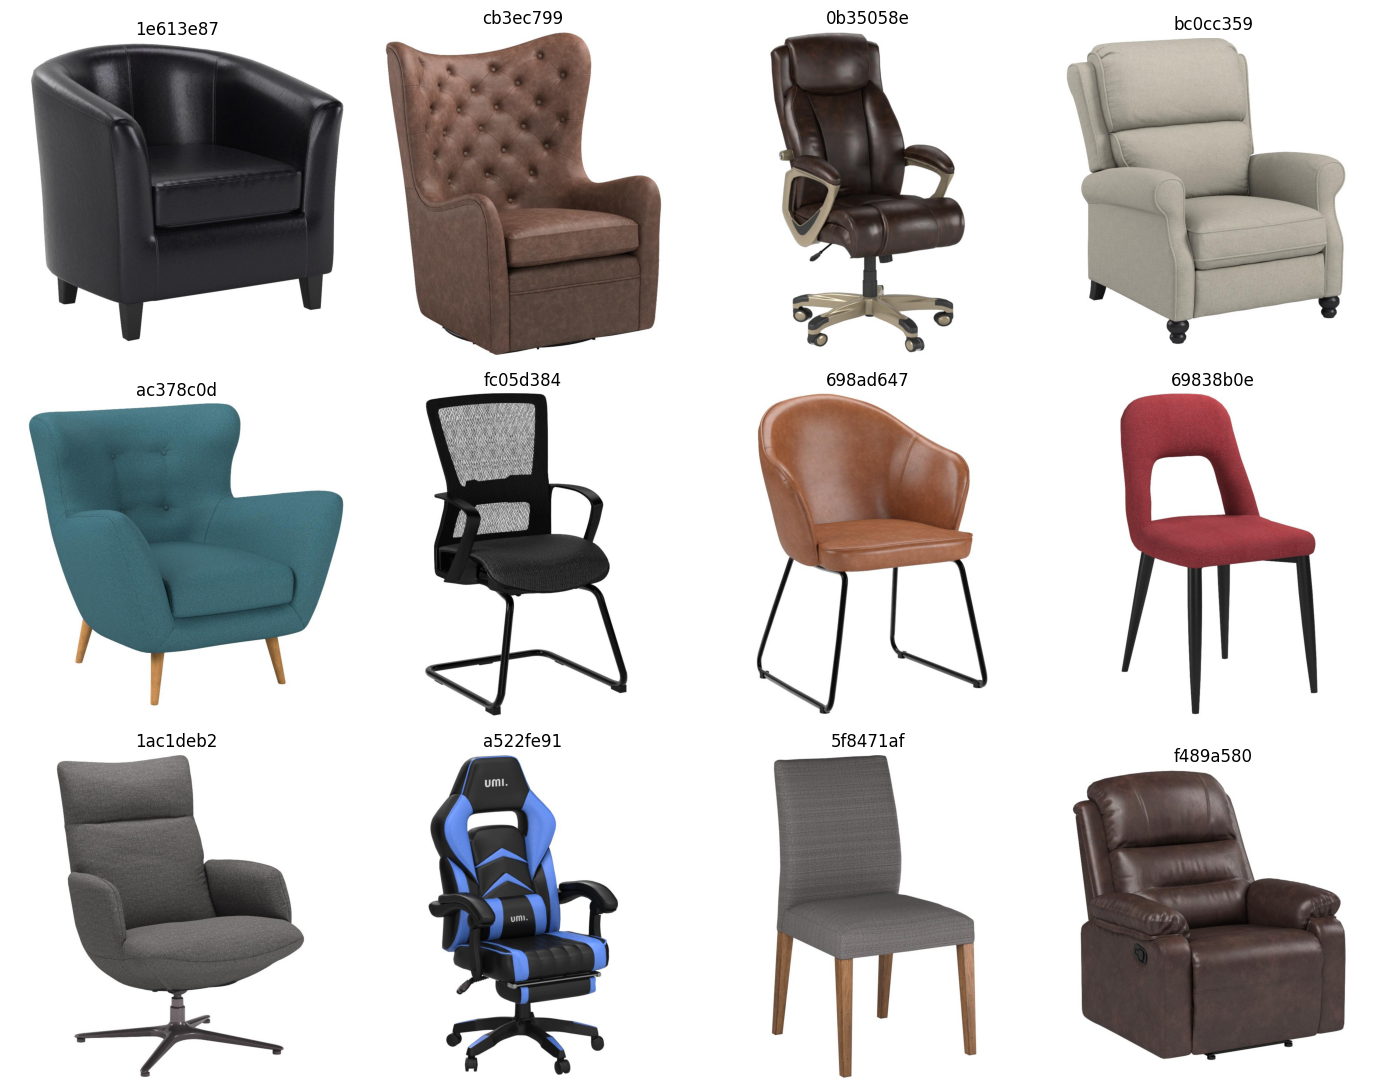

In [2]:
import matplotlib.pyplot as plt
from PIL import Image

# compare other chairs before choosing the next pilot
candidate_products = [
    row for row in products
    if row["product_type"] == "CHAIR"
    and row["spin_id"] != product_id
][:12]

fig, axes = plt.subplots(3, 4, figsize=(14, 11))

for ax in axes.flat:
    ax.axis("off")

for ax, candidate in zip(axes.flat, candidate_products):
    path = (
        data_root / "images"
        / candidate["product_type"]
        / candidate["spin_id"]
        / "00.jpg"
    )

    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(candidate["spin_id"])

plt.tight_layout()
plt.show()

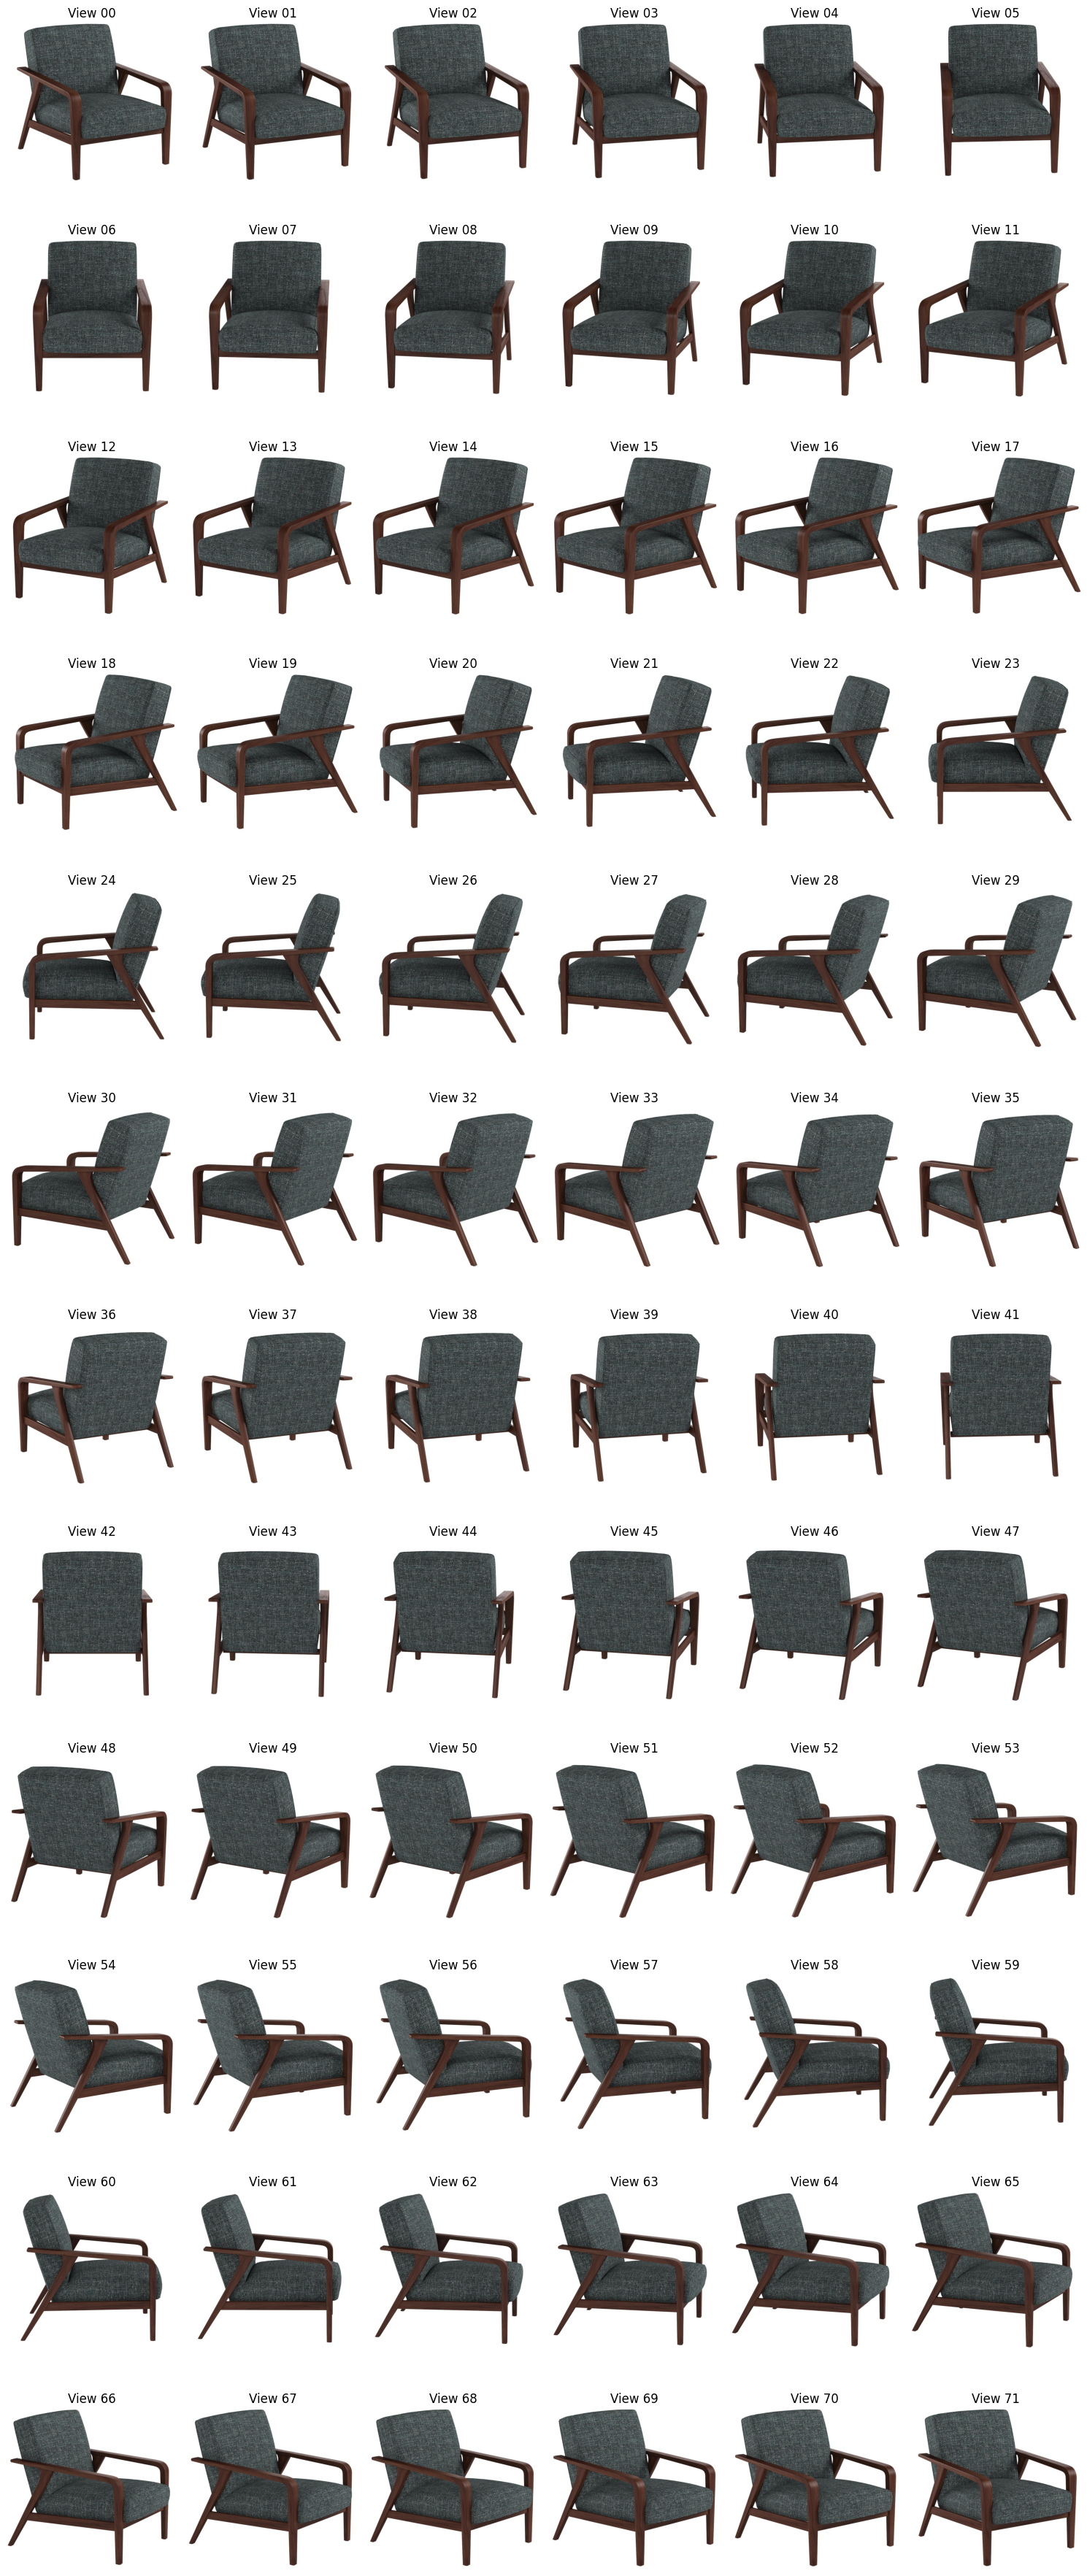

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
import math

# use six images per row so the rotation is easy to inspect
num_columns = 6
num_rows = math.ceil(len(image_paths) / num_columns)

fig, axes = plt.subplots(
    num_rows,
    num_columns,
    figsize=(15, num_rows * 3),
    squeeze=False,
)

for ax in axes.flat:
    ax.axis("off")

# check that the images show the same object through a full rotation
for ax, index, path in zip(axes.flat, view_indices, image_paths):
    with Image.open(path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"View {index:02d}")

plt.tight_layout()
plt.show()

## Installing & Checking COLMAP

In [4]:
import os
import shutil
import subprocess

# allow colmap to run without a graphical display
os.environ["QT_QPA_PLATFORM"] = "offscreen"

install_log = work_root / "colmap_install.log"

# skip installation if colmap is already available in this session
if shutil.which("colmap") is None:
    commands = [
        ["apt-get", "update", "-qq"],
        ["apt-get", "install", "-y", "colmap"],
    ]

    with install_log.open("w") as log:
        for command in commands:
            result = subprocess.run(
                command,
                stdout=log,
                stderr=subprocess.STDOUT,
            )

            if result.returncode != 0:
                # show the end of the log to help identify the problem
                log.flush()
                print(install_log.read_text()[-6000:])
                raise RuntimeError("COLMAP installation failed.")
else:
    print("COLMAP is already installed.")

# check that the executable starts correctly
result = subprocess.run(
    ["colmap", "-h"],
    capture_output=True,
    text=True,
)

colmap_help = result.stdout + result.stderr
print(colmap_help[:2500])

if result.returncode != 0:
    raise RuntimeError("COLMAP could not start.")

COLMAP 3.9.1 -- Structure-from-Motion and Multi-View Stereo
(Commit Unknown on Unknown without CUDA)

Usage:
  colmap [command] [options]

Documentation:
  https://colmap.github.io/

Example usage:
  colmap help [ -h, --help ]
  colmap gui
  colmap gui -h [ --help ]
  colmap automatic_reconstructor -h [ --help ]
  colmap automatic_reconstructor --image_path IMAGES --workspace_path WORKSPACE
  colmap feature_extractor --image_path IMAGES --database_path DATABASE
  colmap exhaustive_matcher --database_path DATABASE
  colmap mapper --image_path IMAGES --database_path DATABASE --output_path MODEL
  ...

Available commands:
  help
  gui
  automatic_reconstructor
  bundle_adjuster
  color_extractor
  database_cleaner
  database_creator
  database_merger
  delaunay_mesher
  exhaustive_matcher
  feature_extractor
  feature_importer
  hierarchical_mapper
  image_deleter
  image_filterer
  image_rectifier
  image_registrator
  image_undistorter
  image_undistorter_standalone
  mapper
  matches_i

## Prepping Working (Reconstruction) Folder Directory

In [5]:
import hashlib
import json

# keep each product and image count in its own folder
run_root = work_root / f"{product_id}_{num_views}views"
input_folder = run_root / "input"
database_path = run_root / "database.db"

input_folder.mkdir(parents=True, exist_ok=True)

# prevent an existing database from mixing different image selections
selection_path = run_root / "selection.json"

selection = {
    "product_id": product_id,
    "num_views": num_views,
    "view_indices": view_indices,
    "images": [],
}

for source in image_paths:
    image_hash = hashlib.sha256(source.read_bytes()).hexdigest()

    selection["images"].append({
        "name": source.name,
        "sha256": image_hash,
    })

if selection_path.exists():
    previous_selection = json.loads(selection_path.read_text())

    if previous_selection != selection:
        raise RuntimeError(
            "This folder contains a different image selection. "
            "Choose a new run folder."
        )
elif database_path.exists():
    raise RuntimeError(
        "An existing database has no selection record. "
        "Choose a new run folder."
    )

# copy the images because kaggle input folders are read-only
for source in image_paths:
    shutil.copy2(source, input_folder / source.name)

selection_path.write_text(json.dumps(selection, indent=2))

print("Run folder:", run_root)
print("Images prepared:", len(image_paths))

Run folder: /kaggle/working/splatify/d3e97083_72views
Images prepared: 72


## Extract and Match Features

In [6]:
# keep the stronger-feature attempt separate from the original run
run_root = work_root / f"{product_id}_{num_views}views_dsp"
input_folder = run_root / "input"
database_path = run_root / "database.db"

# start with a fresh database because the feature settings are changing
if database_path.exists():
    raise RuntimeError(
        "This attempt already has a database. "
        "Inspect its results before running it again."
    )

input_folder.mkdir(parents=True, exist_ok=True)

for source in image_paths:
    shutil.copy2(source, input_folder / source.name)

selection_path = run_root / "selection.json"
selection_path.write_text(json.dumps(selection, indent=2))


# save each stage's output and show errors if it fails
def run_colmap(stage, arguments):
    log_path = run_root / f"{stage}.log"
    command = ["colmap"] + [str(value) for value in arguments]

    print(f"Starting {stage}...")

    with log_path.open("w") as log:
        result = subprocess.run(
            command,
            stdout=log,
            stderr=subprocess.STDOUT,
        )

    if result.returncode != 0:
        print(log_path.read_text()[-6000:])
        raise RuntimeError(f"{stage} failed. See {log_path}")

    print(f"Finished {stage}. Log: {log_path.name}")


# use affine shape estimation and domain-size pooling for stronger features
run_colmap("feature_extraction", [
    "feature_extractor",
    "--database_path", database_path,
    "--image_path", input_folder,
    "--ImageReader.single_camera", "1",
    "--ImageReader.camera_model", "SIMPLE_RADIAL",
    "--SiftExtraction.use_gpu", "0",
    "--SiftExtraction.num_threads", "2",
    "--SiftExtraction.estimate_affine_shape", "1",
    "--SiftExtraction.domain_size_pooling", "1",
])

# use verified geometry to guide additional feature matching
run_colmap("feature_matching", [
    "exhaustive_matcher",
    "--database_path", database_path,
    "--SiftMatching.use_gpu", "0",
    "--SiftMatching.num_threads", "2",
    "--SiftMatching.guided_matching", "1",
])

Starting feature_extraction...
Finished feature_extraction. Log: feature_extraction.log
Starting feature_matching...
Finished feature_matching. Log: feature_matching.log


## Reconstruct the Cameras

In [7]:
# keep the sparse reconstruction separate from the image database
sparse_folder = run_root / "sparse"

# avoid mixing a new reconstruction with an earlier attempt
if sparse_folder.exists() and any(sparse_folder.iterdir()):
    raise RuntimeError(
        "The sparse folder already contains results. "
        "Inspect them before running reconstruction again."
    )

sparse_folder.mkdir(exist_ok=True)

run_colmap("camera_reconstruction", [
    "mapper",
    "--database_path", database_path,
    "--image_path", input_folder,
    "--output_path", sparse_folder,
    "--Mapper.num_threads", "2",
])

Starting camera_reconstruction...
Finished camera_reconstruction. Log: camera_reconstruction.log


## Check Registered Cameras and Sparse Points

In [8]:
import struct

# find the sparse models produced by colmap
model_folders = sorted(
    folder
    for folder in sparse_folder.iterdir()
    if folder.is_dir() and (folder / "images.bin").is_file()
)

if not model_folders:
    print((run_root / "camera_reconstruction.log").read_text()[-6000:])
    raise RuntimeError("COLMAP did not produce a sparse reconstruction.")

model_summary = []

# read the number of registered cameras and reconstructed points
for folder in model_folders:
    with (folder / "images.bin").open("rb") as file:
        registered_images = struct.unpack("<Q", file.read(8))[0]

    with (folder / "points3D.bin").open("rb") as file:
        sparse_points = struct.unpack("<Q", file.read(8))[0]

    model_summary.append({
        "model": folder.name,
        "registered_images": registered_images,
        "sparse_points": sparse_points,
    })

    print(
        f"Model {folder.name}: "
        f"{registered_images}/{num_views} images registered, "
        f"{sparse_points} sparse points"
    )

# save the results before checking whether training can proceed
(run_root / "reconstruction_summary.json").write_text(
    json.dumps(model_summary, indent=2)
)

# find models that registered every selected image
complete_models = [
    summary
    for summary in model_summary
    if summary["registered_images"] == num_views
    and summary["sparse_points"] > 0
]

if len(complete_models) != 1:
    raise RuntimeError(
        f"Expected one complete reconstruction, found {len(complete_models)}. "
        "Inspect the models before selecting one."
    )

# select the complete reconstruction and preserve the other results
selected_model = complete_models[0]
colmap_model = sparse_folder / selected_model["model"]

print("\nSelected model:", selected_model["model"])
print("Registered images:", selected_model["registered_images"])
print("Sparse points:", selected_model["sparse_points"])
print("Model folder:", colmap_model)
print("\nCoverage check passed. Camera geometry still needs inspection.")

Model 0: 3/72 images registered, 1382 sparse points
Model 1: 72/72 images registered, 13491 sparse points

Selected model: 1
Registered images: 72
Sparse points: 13491
Model folder: /kaggle/working/splatify/d3e97083_72views_dsp/sparse/1

Coverage check passed. Camera geometry still needs inspection.


## Exporting Readable Model 1 + Plotting Reconstruction

Starting model_export...
Finished model_export. Log: model_export.log


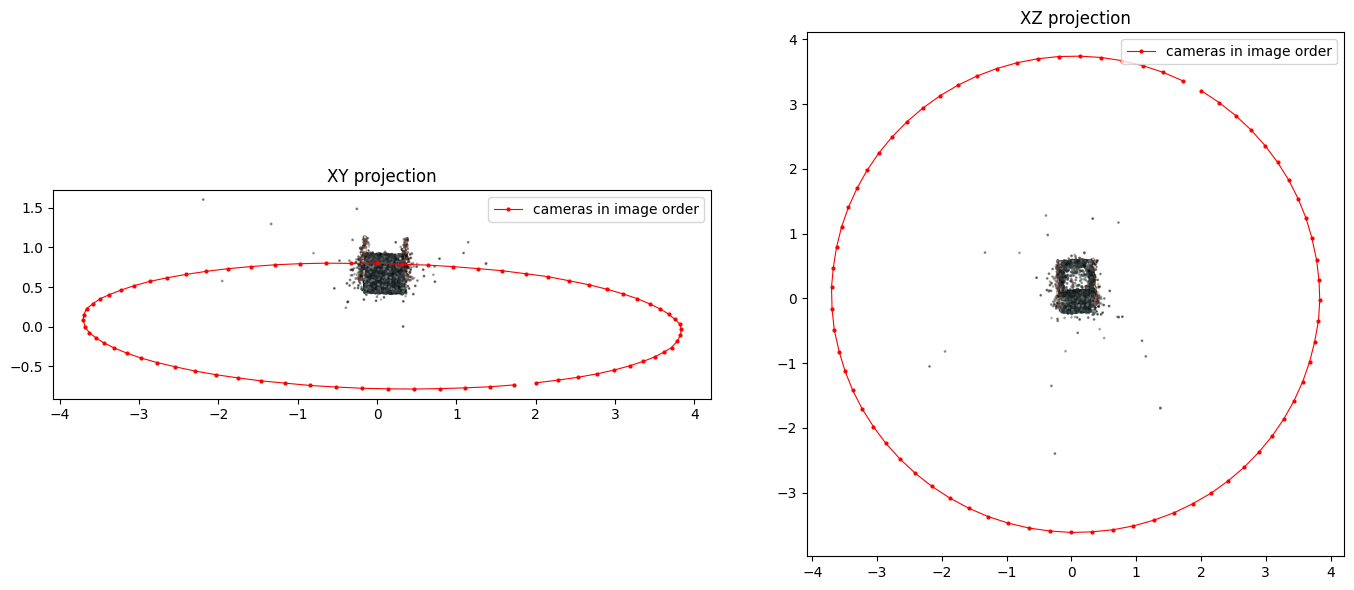

Registered cameras: 72
Sparse points: 13491
Median point reprojection error: 0.66 pixels

Camera parameters:
# Camera list with one line of data per camera:
#   CAMERA_ID, MODEL, WIDTH, HEIGHT, PARAMS[]
# Number of cameras: 1
1 SIMPLE_RADIAL 985 926 4261.5287927275358 492.5 463 -0.21824956346983673



In [9]:
import numpy as np
import matplotlib.pyplot as plt

# export a readable copy of the selected reconstruction
text_folder = run_root / "selected_model_text"
text_folder.mkdir(exist_ok=True)

run_colmap("model_export", [
    "model_converter",
    "--input_path", colmap_model,
    "--output_path", text_folder,
    "--output_type", "TXT",
])

# read the reconstructed points and their colors
points = []
colors = []
errors = []

with (text_folder / "points3D.txt").open() as file:
    for line in file:
        if line.startswith("#") or not line.strip():
            continue

        values = line.split()
        points.append([float(value) for value in values[1:4]])
        colors.append([int(value) for value in values[4:7]])
        errors.append(float(values[7]))

points = np.array(points)
colors = np.array(colors) / 255.0

# read camera poses, skipping the observation line after each pose
camera_centers = []
image_names = []

with (text_folder / "images.txt").open() as file:
    while True:
        line = file.readline()

        if not line:
            break

        if line.startswith("#") or not line.strip():
            continue

        values = line.split()
        qw, qx, qy, qz = map(float, values[1:5])
        translation = np.array(list(map(float, values[5:8])))

        rotation = np.array([
            [
                1 - 2 * (qy**2 + qz**2),
                2 * (qx*qy - qw*qz),
                2 * (qx*qz + qw*qy),
            ],
            [
                2 * (qx*qy + qw*qz),
                1 - 2 * (qx**2 + qz**2),
                2 * (qy*qz - qw*qx),
            ],
            [
                2 * (qx*qz - qw*qy),
                2 * (qy*qz + qw*qx),
                1 - 2 * (qx**2 + qy**2),
            ],
        ])

        # convert the world-to-camera pose into a camera position
        camera_centers.append(-rotation.T @ translation)
        image_names.append(values[9])

        # each pose is followed by one line of image observations
        file.readline()

camera_centers = np.array(camera_centers)

# connect camera positions in the original image order
order = np.argsort(image_names)
camera_centers = camera_centers[order]

# show two projections because colmap's world axes are arbitrary
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, dimensions, title in [
    (axes[0], (0, 1), "XY projection"),
    (axes[1], (0, 2), "XZ projection"),
]:
    x, y = dimensions

    ax.scatter(
        points[:, x],
        points[:, y],
        c=colors,
        s=1,
        alpha=0.5,
    )

    ax.plot(
        camera_centers[:, x],
        camera_centers[:, y],
        "r.-",
        markersize=4,
        linewidth=0.8,
        label="cameras in image order",
    )

    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.legend()

plt.tight_layout()
plt.show()

print("Registered cameras:", len(camera_centers))
print("Sparse points:", len(points))
print(f"Median point reprojection error: {np.median(errors):.2f} pixels")

# display the estimated camera parameters for inspection
print("\nCamera parameters:")
print((text_folder / "cameras.txt").read_text())

## Undistort Image + Prepping for 3DGS run (file rearrangement)

In [10]:
# create a separate folder for the gaussian splatting inputs
scene_folder = run_root / "gs_scene"

if scene_folder.exists():
    raise RuntimeError(
        "The training scene folder already exists. "
        "Inspect its contents before running this cell again."
    )

scene_folder.mkdir()

# convert the images and cameras to an undistorted pinhole model
run_colmap("image_undistortion", [
    "image_undistorter",
    "--image_path", input_folder,
    "--input_path", colmap_model,
    "--output_path", scene_folder,
    "--output_type", "COLMAP",
])

# arrange the sparse model in the directory expected by official 3dgs
sparse_output = scene_folder / "sparse"
training_model = sparse_output / "0"
training_model.mkdir(exist_ok=True)

for filename in ["cameras.bin", "images.bin", "points3D.bin"]:
    source = sparse_output / filename
    destination = training_model / filename

    if source.is_file():
        shutil.move(str(source), str(destination))

    if not destination.is_file():
        raise FileNotFoundError(f"Missing training input: {destination}")

# check that every registered image has an undistorted image file
undistorted_images = [
    path
    for path in (scene_folder / "images").iterdir()
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if len(undistorted_images) != num_views:
    raise RuntimeError(
        f"Expected {num_views} images, found {len(undistorted_images)}."
    )

# record the selected reconstruction and preprocessing settings
preparation_info = {
    "product_id": product_id,
    "num_views": num_views,
    "selected_model": colmap_model.name,
    "feature_method": "affine SIFT with domain-size pooling",
    "guided_matching": True,
    "training_scene": str(scene_folder),
    "reference_mesh_used": False,
}

(scene_folder / "preparation.json").write_text(
    json.dumps(preparation_info, indent=2)
)

print("Training scene:", scene_folder)
print("Undistorted images:", len(undistorted_images))
print("Sparse model:", training_model)
print("\nCPU preparation complete.")

Starting image_undistortion...
Finished image_undistortion. Log: image_undistortion.log
Training scene: /kaggle/working/splatify/d3e97083_72views_dsp/gs_scene
Undistorted images: 72
Sparse model: /kaggle/working/splatify/d3e97083_72views_dsp/gs_scene/sparse/0

CPU preparation complete.


## Saving Scene

In [11]:
from IPython.display import FileLink, display

# package the prepared images, cameras, and sparse points
archive_path = shutil.make_archive(
    str(work_root / f"{product_id}_{num_views}views_prepared"),
    "zip",
    root_dir=scene_folder.parent,
    base_dir=scene_folder.name,
)

archive_path = Path(archive_path)

# check that the archive contains the required training inputs
with zipfile.ZipFile(archive_path) as archive:
    required_files = [
        "gs_scene/sparse/0/cameras.bin",
        "gs_scene/sparse/0/images.bin",
        "gs_scene/sparse/0/points3D.bin",
        "gs_scene/preparation.json",
    ]

    missing_files = [
        name for name in required_files
        if name not in archive.namelist()
    ]

    if missing_files:
        raise RuntimeError(f"Missing files in archive: {missing_files}")

print("Saved:", archive_path)
print(f"Archive size: {archive_path.stat().st_size / 1024**2:.1f} MB")

display(FileLink(str(archive_path)))

Saved: /kaggle/working/splatify/d3e97083_72views_prepared.zip
Archive size: 26.9 MB


/kaggle/working/splatify/d3e97083_72views_prepared.zip

## Check GPU Environment and prepped scene

In [1]:
from pathlib import Path
import subprocess
import sys

# check which gpu kaggle assigned to this session
result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
)

print(result.stdout or result.stderr)

if result.returncode != 0:
    raise RuntimeError("No working NVIDIA GPU was found.")

# inspect the existing pytorch and cuda versions before installing anything
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("PyTorch cannot access the GPU.")

# check whether the cuda compiler is available for building 3dgs extensions
compiler = subprocess.run(
    ["bash", "-lc", "command -v nvcc && nvcc --version"],
    capture_output=True,
    text=True,
)

print("\nCUDA compiler:")
print(compiler.stdout or compiler.stderr)

# restore the scene path because switching sessions may clear variables
scene_folder = Path(
    "/kaggle/working/splatify/d3e97083_72views_dsp/gs_scene"
)

required_files = [
    scene_folder / "sparse/0/cameras.bin",
    scene_folder / "sparse/0/images.bin",
    scene_folder / "sparse/0/points3D.bin",
]

scene_available = (
    (scene_folder / "images").is_dir()
    and all(path.is_file() for path in required_files)
)

print("\nPrepared scene available:", scene_available)
print("Scene folder:", scene_folder)

if scene_available:
    image_count = sum(
        path.suffix.lower() in [".jpg", ".jpeg", ".png"]
        for path in (scene_folder / "images").iterdir()
    )
    print("Prepared images:", image_count)
else:
    print("We need to restore the prepared-scene ZIP before training.")

Fri Nov 13 17:24:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Restoration cause of the GPU switching

In [2]:
import shutil
import zipfile

# locate the prepared scene in the attached dataset
attached_folder = Path(
    "/kaggle/input/datasets/chaitanyapeshin/splatify"
)

if not attached_folder.is_dir():
    raise FileNotFoundError(
        f"Attached dataset folder not found: {attached_folder}"
    )

scene_folder = Path(
    "/kaggle/working/splatify/d3e97083_72views_dsp/gs_scene"
)

# look for an already extracted colmap scene
scene_candidates = [
    path.parent.parent.parent
    for path in attached_folder.rglob("cameras.bin")
    if path.parent.name == "0"
    and path.parent.parent.name == "sparse"
    and (path.parent / "images.bin").is_file()
    and (path.parent / "points3D.bin").is_file()
    and (path.parent.parent.parent / "images").is_dir()
]

if scene_folder.exists():
    raise RuntimeError(
        "The destination already exists. Inspect it before restoring again."
    )

if len(scene_candidates) == 1:
    # copy the prepared scene into writable storage
    scene_folder.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(scene_candidates[0], scene_folder)

elif len(scene_candidates) > 1:
    raise RuntimeError(
        "Multiple prepared scenes were found. Select the intended scene."
    )

else:
    # find the archive containing the prepared scene
    matching_archives = []

    for archive_path in attached_folder.rglob("*.zip"):
        with zipfile.ZipFile(archive_path) as archive:
            if "gs_scene/sparse/0/cameras.bin" in archive.namelist():
                matching_archives.append(archive_path)

    if len(matching_archives) != 1:
        print("Attached files:")
        for path in list(attached_folder.rglob("*"))[:40]:
            print(path)

        raise RuntimeError(
            f"Expected one prepared-scene ZIP, found {len(matching_archives)}."
        )

    destination = scene_folder.parent
    destination.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(matching_archives[0]) as archive:
        # check that archive entries stay inside the destination
        for entry in archive.infolist():
            target = (destination / entry.filename).resolve()

            if not target.is_relative_to(destination.resolve()):
                raise ValueError(f"Unsafe archive path: {entry.filename}")

        archive.extractall(destination)

# verify the restored camera model and image files
for filename in ["cameras.bin", "images.bin", "points3D.bin"]:
    path = scene_folder / "sparse" / "0" / filename

    if not path.is_file():
        raise FileNotFoundError(f"Missing prepared file: {path}")

prepared_images = [
    path
    for path in (scene_folder / "images").iterdir()
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

if len(prepared_images) != 72:
    raise RuntimeError(
        f"Expected 72 prepared images, found {len(prepared_images)}."
    )

print("Scene restored:", scene_folder)
print("Prepared images:", len(prepared_images))
print("Camera model and sparse points: present")

Scene restored: /kaggle/working/splatify/d3e97083_72views_dsp/gs_scene
Prepared images: 72
Camera model and sparse points: present


## Creating the Training Environment

In [3]:
import os
import subprocess
from pathlib import Path

# keep installed software outside the folder used for saved results
software_root = Path("/kaggle/temp/splatify")
software_root.mkdir(parents=True, exist_ok=True)

mamba_path = software_root / "bin/micromamba"
env_path = software_root / "env"
setup_log = Path("/kaggle/working/3dgs_environment_setup.log")

# download the standalone environment manager
if not mamba_path.is_file():
    archive_path = software_root / "micromamba.tar.bz2"

    subprocess.run([
        "curl", "-L", "--fail",
        "https://micro.mamba.pm/api/micromamba/linux-64/latest",
        "-o", str(archive_path),
    ], check=True)

    subprocess.run([
        "tar", "-xjf", str(archive_path),
        "-C", str(software_root),
        "bin/micromamba",
    ], check=True)

# create an isolated python, pytorch, and cuda installation
setup_env = os.environ.copy()
setup_env["MAMBA_ROOT_PREFIX"] = str(software_root / "mamba")

command = [
    str(mamba_path),
    "create", "-y",
    "-p", str(env_path),
    "--override-channels",
    "-c", "pytorch",
    "-c", "nvidia",
    "-c", "conda-forge",
    "python=3.10",
    "pytorch=2.1.2",
    "torchvision=0.16.2",
    "pytorch-cuda=11.8",
    "cuda-toolkit=11.8",
    "gxx_linux-64=11",
    "numpy<2",
    "pip",
    "setuptools<70",
    "wheel",
    "ninja",
    "pillow=9.5",
    "plyfile=0.8.1",
    "tqdm",
]

if not (env_path / "bin/python").is_file():
    print("Installing the training environment. Details are saved to:", setup_log)

    with setup_log.open("w") as log:
        result = subprocess.run(
            command,
            env=setup_env,
            stdout=log,
            stderr=subprocess.STDOUT,
        )

    if result.returncode != 0:
        print(setup_log.read_text()[-8000:])
        raise RuntimeError("Environment installation failed.")
else:
    print("An environment already exists; checking it below.")

# use this interpreter for training rather than the notebook's interpreter
training_python = env_path / "bin/python"

check_code = """
import sys
import torch

print("Training Python:", sys.version.split()[0])
print("Training PyTorch:", torch.__version__)
print("Training CUDA:", torch.version.cuda)
print("GPU accessible:", torch.cuda.is_available())

assert torch.cuda.is_available(), "The training environment cannot access CUDA."
print("GPU:", torch.cuda.get_device_name(0))
"""

subprocess.run(
    [str(training_python), "-c", check_code],
    check=True,
)

subprocess.run(
    [str(env_path / "bin/nvcc"), "--version"],
    check=True,
)

print("\nEnvironment check complete.")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 7146k  100 7146k    0     0  8980k      0 --:--:-- --:--:-- --:--:-- 8980k


Installing the training environment. Details are saved to: /kaggle/working/3dgs_environment_setup.log
Training Python: 3.10.22
Training PyTorch: 2.1.2
Training CUDA: 11.8
GPU accessible: True
GPU: Tesla T4
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2026 NVIDIA Corporation
Built on Fri_Apr_24_07:22:02_PM_PDT_2026
Cuda compilation tools, release 13.3, V13.3.33
Build cuda_13.3.r13.3/compiler.37862127_0

Environment check complete.


## Pinning Compiler and Dev Headers to CUDA

In [4]:
# pin the compiler and headers to match pytorch's cuda version
fix_command = [
    str(mamba_path),
    "install", "-y",
    "-p", str(env_path),
    "--override-channels",
    "-c", "pytorch",
    "-c", "nvidia",
    "-c", "conda-forge",
    "python=3.10",
    "pytorch=2.1.2",
    "torchvision=0.16.2",
    "pytorch-cuda=11.8",
    "cuda-nvcc=11.8",
    "cuda-cudart=11.8",
    "cuda-cudart-dev=11.8",
    "cuda-cccl=11.8",
]

fix_log = Path("/kaggle/working/3dgs_cuda_fix.log")

with fix_log.open("w") as log:
    result = subprocess.run(
        fix_command,
        env=setup_env,
        stdout=log,
        stderr=subprocess.STDOUT,
    )

if result.returncode != 0:
    print(fix_log.read_text()[-8000:])
    raise RuntimeError("CUDA compiler installation failed.")

# explicitly select the isolated toolkit for future extension builds
build_env = os.environ.copy()
build_env["CUDA_HOME"] = str(env_path)
build_env["PATH"] = str(env_path / "bin") + os.pathsep + build_env["PATH"]
build_env["MAX_JOBS"] = "2"
build_env["TORCH_CUDA_ARCH_LIST"] = "7.5"

compiler_check = subprocess.run(
    [str(env_path / "bin/nvcc"), "--version"],
    env=build_env,
    capture_output=True,
    text=True,
    check=True,
)

print(compiler_check.stdout)

# stop here if the compiler still does not match pytorch
if "release 11.8," not in compiler_check.stdout:
    raise RuntimeError("Expected the CUDA 11.8 compiler.")

subprocess.run(
    [str(training_python), "-c", """
import torch

print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)

assert torch.version.cuda == "11.8"
assert torch.cuda.is_available()

print("GPU:", torch.cuda.get_device_name(0))
"""],
    env=build_env,
    check=True,
)

print("\nCUDA version checks passed.")

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2022 NVIDIA Corporation
Built on Wed_Sep_21_10:33:58_PDT_2022
Cuda compilation tools, release 11.8, V11.8.89
Build cuda_11.8.r11.8/compiler.31833905_0

PyTorch: 2.1.2
PyTorch CUDA: 11.8
GPU: Tesla T4

CUDA version checks passed.


## Download Pinned Vanilla 3DGS Source + Building the two needed CUDA extensions

In [5]:
# use a fixed version of the original 3dgs implementation
gs_folder = software_root / "gaussian-splatting"
gs_commit = "2eee0e26d2d5fd00ec462df47752223952f6bf4e"

if not gs_folder.exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/graphdeco-inria/gaussian-splatting.git",
        str(gs_folder),
    ], check=True)

subprocess.run([
    "git", "-C", str(gs_folder),
    "checkout", gs_commit,
], check=True)

# download only the submodules needed for training
subprocess.run([
    "git", "-C", str(gs_folder),
    "submodule", "update", "--init", "--recursive",
    "submodules/diff-gaussian-rasterization",
    "submodules/simple-knn",
], check=True)

# use the gcc 11 compilers installed in the isolated environment
build_env["CC"] = str(env_path / "bin/x86_64-conda-linux-gnu-cc")
build_env["CXX"] = str(env_path / "bin/x86_64-conda-linux-gnu-c++")
build_env["CUDA_VISIBLE_DEVICES"] = "0"

for variable in ["CC", "CXX"]:
    if not Path(build_env[variable]).is_file():
        raise FileNotFoundError(
            f"Compiler not found: {build_env[variable]}"
        )

# compile the rasterizer and nearest-neighbor extensions
build_log = Path("/kaggle/working/3dgs_extension_build.log")

print("Building extensions. This may take several minutes.")
print("Build log:", build_log)

with build_log.open("w") as log:
    result = subprocess.run([
        str(training_python),
        "-m", "pip", "install",
        "--no-build-isolation",
        "--no-deps",
        "-v",
        str(gs_folder / "submodules/diff-gaussian-rasterization"),
        str(gs_folder / "submodules/simple-knn"),
    ], env=build_env, stdout=log, stderr=subprocess.STDOUT)

if result.returncode != 0:
    print(build_log.read_text()[-10000:])
    raise RuntimeError("3DGS extension compilation failed.")

# check the compiled modules and run a small cuda operation
extension_check = """
import torch
import diff_gaussian_rasterization._C
import simple_knn._C

x = torch.ones(4, device="cuda")
assert x.sum().item() == 4

print("Rasterizer extension: loaded")
print("Nearest-neighbor extension: loaded")
print("CUDA tensor check: passed")
print("GPU:", torch.cuda.get_device_name(0))
"""

subprocess.run(
    [str(training_python), "-c", extension_check],
    env=build_env,
    check=True,
)

print("\n3DGS extensions are ready.")

Cloning into '/kaggle/temp/splatify/gaussian-splatting'...
Note: switching to '2eee0e26d2d5fd00ec462df47752223952f6bf4e'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 2eee0e2 Bumped sibr viewers
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/graphdeco-inria/diff-gaussian-rasterization) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/

Submodule path 'submodules/diff-gaussian-rasterization': checked out '59f5f77e3ddbac3ed9db93ec2cfe99ed6c5d121d'


Submodule 'third_party/glm' (https://github.com/g-truc/glm.git) registered for path 'submodules/diff-gaussian-rasterization/third_party/glm'
Cloning into '/kaggle/temp/splatify/gaussian-splatting/submodules/diff-gaussian-rasterization/third_party/glm'...


Submodule path 'submodules/diff-gaussian-rasterization/third_party/glm': checked out '5c46b9c07008ae65cb81ab79cd677ecc1934b903'
Submodule path 'submodules/simple-knn': checked out '44f764299fa305faf6ec5ebd99939e0508331503'
Building extensions. This may take several minutes.
Build log: /kaggle/working/3dgs_extension_build.log
Rasterizer extension: loaded
Nearest-neighbor extension: loaded
CUDA tensor check: passed
GPU: Tesla T4

3DGS extensions are ready.


## First Training Functionality Test - 1k Iterations (just for Pilots)

In [6]:
import json
import time

# keep the pilot separate from future full training runs
pilot_folder = Path("/kaggle/working/3dgs_runs/d3e97083_72views_pilot")
pilot_log = Path("/kaggle/working/3dgs_pilot_training.log")

if pilot_folder.exists():
    raise RuntimeError(
        "The pilot output folder already exists. "
        "Inspect its results before starting another run."
    )

pilot_folder.parent.mkdir(parents=True, exist_ok=True)

# record the settings used for this experiment
pilot_settings = {
    "product_id": "d3e97083",
    "training_images": 72,
    "iterations": 1000,
    "resolution_downsample": 2,
    "source_commit": gs_commit,
    "scene_folder": str(scene_folder),
    "evaluation_split": False,
    "purpose": "functionality and memory smoke test",
}

# train the original implementation without changing its source
training_command = [
    str(training_python),
    str(gs_folder / "train.py"),
    "--source_path", str(scene_folder),
    "--model_path", str(pilot_folder),
    "--resolution", "2",
    "--iterations", "1000",
    "--save_iterations", "1000",
    "--checkpoint_iterations", "1000",
    "--test_iterations", "1000",
]

print("Starting the 1000 iteration pilot.")
print("Training log:", pilot_log)

start_time = time.perf_counter()

with pilot_log.open("w") as log:
    result = subprocess.run(
        training_command,
        cwd=gs_folder,
        env=build_env,
        stdout=log,
        stderr=subprocess.STDOUT,
    )

elapsed_seconds = time.perf_counter() - start_time

# preserve the settings and timing even if training fails
pilot_folder.mkdir(parents=True, exist_ok=True)
pilot_settings["elapsed_seconds"] = elapsed_seconds
pilot_settings["return_code"] = result.returncode

(pilot_folder / "experiment.json").write_text(
    json.dumps(pilot_settings, indent=2)
)

print(pilot_log.read_text(errors="replace")[-6000:])

if result.returncode != 0:
    raise RuntimeError("Pilot training failed. See the log above.")

# check that both the gaussian representation and checkpoint were saved
gaussian_file = (
    pilot_folder / "point_cloud" / "iteration_1000" / "point_cloud.ply"
)
checkpoint_file = pilot_folder / "chkpnt1000.pth"

for path in [gaussian_file, checkpoint_file]:
    if not path.is_file():
        raise FileNotFoundError(f"Expected output missing: {path}")

print(f"\nPilot completed in {elapsed_seconds / 60:.2f} minutes.")
print("Gaussian representation:", gaussian_file)
print("Resumable checkpoint:", checkpoint_file)
print(f"Gaussian file size: {gaussian_file.stat().st_size / 1024**2:.1f} MB")

Starting the 1,000-iteration pilot.
Training log: /kaggle/working/3dgs_pilot_training.log
.1245886]
Training progress: 100%|██████████| 1000/1000 [00:13<00:00, 72.59it/s, Loss=0.0965424]

[ITER 1000] Evaluating train: L1 0.07143671587109567 PSNR 18.56770172119141 [13/11 17:45:17]

[ITER 1000] Saving Gaussians [13/11 17:45:17]

[ITER 1000] Saving Checkpoint [13/11 17:45:17]

Training complete. [13/11 17:45:17]


Pilot completed in 0.31 minutes.
Gaussian representation: /kaggle/working/3dgs_runs/d3e97083_72views_pilot/point_cloud/iteration_1000/point_cloud.ply
Resumable checkpoint: /kaggle/working/3dgs_runs/d3e97083_72views_pilot/chkpnt1000.pth
Gaussian file size: 6.1 MB


## Generating Pilot Renders for Comparison (just as a test - for comparing with inputs)

In [7]:
# render the saved model from the training camera positions
render_log = Path("/kaggle/working/3dgs_pilot_render.log")

with render_log.open("w") as log:
    result = subprocess.run([
        str(training_python),
        str(gs_folder / "render.py"),
        "--model_path", str(pilot_folder),
        "--iteration", "1000",
        "--skip_test",
    ], cwd=gs_folder, env=build_env,
       stdout=log, stderr=subprocess.STDOUT)

print(render_log.read_text(errors="replace")[-3000:])

if result.returncode != 0:
    raise RuntimeError("Pilot rendering failed.")

print("Pilot rendering complete.")

84it/s]
Rendering progress: 100%|██████████| 72/72 [00:08<00:00,  8.18it/s]

Pilot rendering complete.


## Pilot Comparison with Input

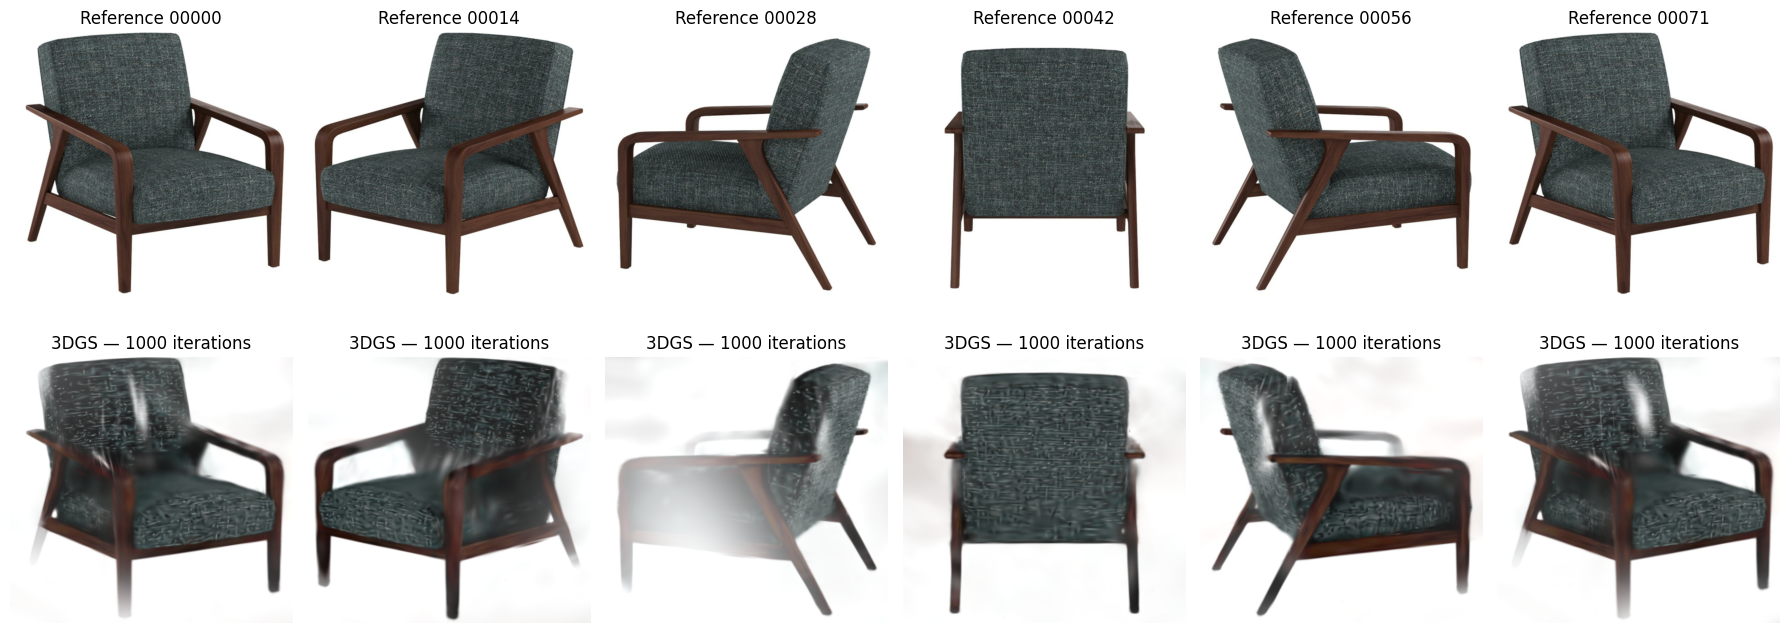

In [14]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# locate the rendered images and matching reference images
render_folder = pilot_folder / "train/ours_1000/renders"
reference_folder = pilot_folder / "train/ours_1000/gt"

render_paths = sorted(render_folder.glob("*.png"))

if not render_paths:
    raise RuntimeError("No rendered images were found.")

# sample views across the saved camera list
sample_indices = np.linspace(
    0, len(render_paths) - 1, 6, dtype=int
)

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for column, index in enumerate(sample_indices):
    render_path = render_paths[index]
    reference_path = reference_folder / render_path.name

    with Image.open(reference_path) as image:
        axes[0, column].imshow(image.convert("RGB"))

    with Image.open(render_path) as image:
        axes[1, column].imshow(image.convert("RGB"))

    axes[0, column].set_title(f"Reference {render_path.stem}")
    axes[1, column].set_title("3DGS — 1000 iterations")

    axes[0, column].axis("off")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

## Baseline with 30k Iterations

In [9]:
# train a fresh baseline while preserving the short pilot
baseline_folder = Path(
    "/kaggle/working/3dgs_runs/d3e97083_72views_30000_halfres"
)
baseline_log = Path("/kaggle/working/3dgs_baseline_training.log")

if baseline_folder.exists():
    raise RuntimeError(
        "The baseline folder already exists. Inspect it before rerunning."
    )

baseline_folder.parent.mkdir(parents=True, exist_ok=True)

# record the configuration before starting training
baseline_settings = {
    "product_id": "d3e97083",
    "training_images": 72,
    "iterations": 30000,
    "resolution_downsample": 2,
    "source_commit": gs_commit,
    "scene_folder": str(scene_folder),
    "evaluation_split": False,
    "initialization": "COLMAP sparse points",
}

training_command = [
    str(training_python),
    str(gs_folder / "train.py"),
    "--source_path", str(scene_folder),
    "--model_path", str(baseline_folder),
    "--resolution", "2",
    "--iterations", "30000",
    "--save_iterations", "7000", "30000",
    "--checkpoint_iterations", "7000", "15000", "30000",
    "--test_iterations", "7000", "30000",
]

print("Starting the 30000 iteration baseline.")
print("Training log:", baseline_log)

start_time = time.perf_counter()

with baseline_log.open("w") as log:
    result = subprocess.run(
        training_command,
        cwd=gs_folder,
        env=build_env,
        stdout=log,
        stderr=subprocess.STDOUT,
    )

elapsed_seconds = time.perf_counter() - start_time

# preserve the configuration and timing even if training fails
baseline_folder.mkdir(parents=True, exist_ok=True)

baseline_settings["elapsed_seconds"] = elapsed_seconds
baseline_settings["return_code"] = result.returncode

(baseline_folder / "experiment.json").write_text(
    json.dumps(baseline_settings, indent=2)
)

print(baseline_log.read_text(errors="replace")[-6000:])

if result.returncode != 0:
    raise RuntimeError("Baseline training failed. See the log above.")

gaussian_file = (
    baseline_folder / "point_cloud/iteration_30000/point_cloud.ply"
)
checkpoint_file = baseline_folder / "chkpnt30000.pth"

for path in [gaussian_file, checkpoint_file]:
    if not path.is_file():
        raise FileNotFoundError(f"Expected output missing: {path}")

print(f"\nTraining completed in {elapsed_seconds / 60:.2f} minutes.")
print(f"Gaussian file size: {gaussian_file.stat().st_size / 1024**2:.1f} MB")
print("Model:", gaussian_file)
print("Checkpoint:", checkpoint_file)

Starting the 30,000-iteration baseline.
Training log: /kaggle/working/3dgs_baseline_training.log
s=0.0058451]
Training progress: 100%|██████████| 30000/30000 [26:31<00:00, 18.85it/s, Loss=0.0060348]

[ITER 7000] Evaluating train: L1 0.01237003542482853 PSNR 29.530742263793947 [13/11 17:52:22]

[ITER 7000] Saving Gaussians [13/11 17:52:22]

[ITER 7000] Saving Checkpoint [13/11 17:52:25]

[ITER 15000] Saving Checkpoint [13/11 18:00:09]

[ITER 30000] Evaluating train: L1 0.004595184419304133 PSNR 37.59810256958008 [13/11 18:15:19]

[ITER 30000] Saving Gaussians [13/11 18:15:19]

[ITER 30000] Saving Checkpoint [13/11 18:15:24]

Training complete. [13/11 18:15:24]


Training completed in 26.69 minutes.
Gaussian file size: 138.4 MB
Model: /kaggle/working/3dgs_runs/d3e97083_72views_30000_halfres/point_cloud/iteration_30000/point_cloud.ply
Checkpoint: /kaggle/working/3dgs_runs/d3e97083_72views_30000_halfres/chkpnt30000.pth


## Rendering Completed Baseline Training

In [10]:
# render the completed baseline from the training cameras
baseline_render_log = Path(
    "/kaggle/working/3dgs_baseline_render.log"
)

with baseline_render_log.open("w") as log:
    result = subprocess.run([
        str(training_python),
        str(gs_folder / "render.py"),
        "--model_path", str(baseline_folder),
        "--iteration", "30000",
        "--skip_test",
    ], cwd=gs_folder, env=build_env,
       stdout=log, stderr=subprocess.STDOUT)

print(baseline_render_log.read_text(errors="replace")[-3000:])

if result.returncode != 0:
    raise RuntimeError("Baseline rendering failed.")

18it/s]
Rendering progress: 100%|██████████| 72/72 [00:08<00:00,  8.73it/s]



## Baseline Comparison with the Input Images

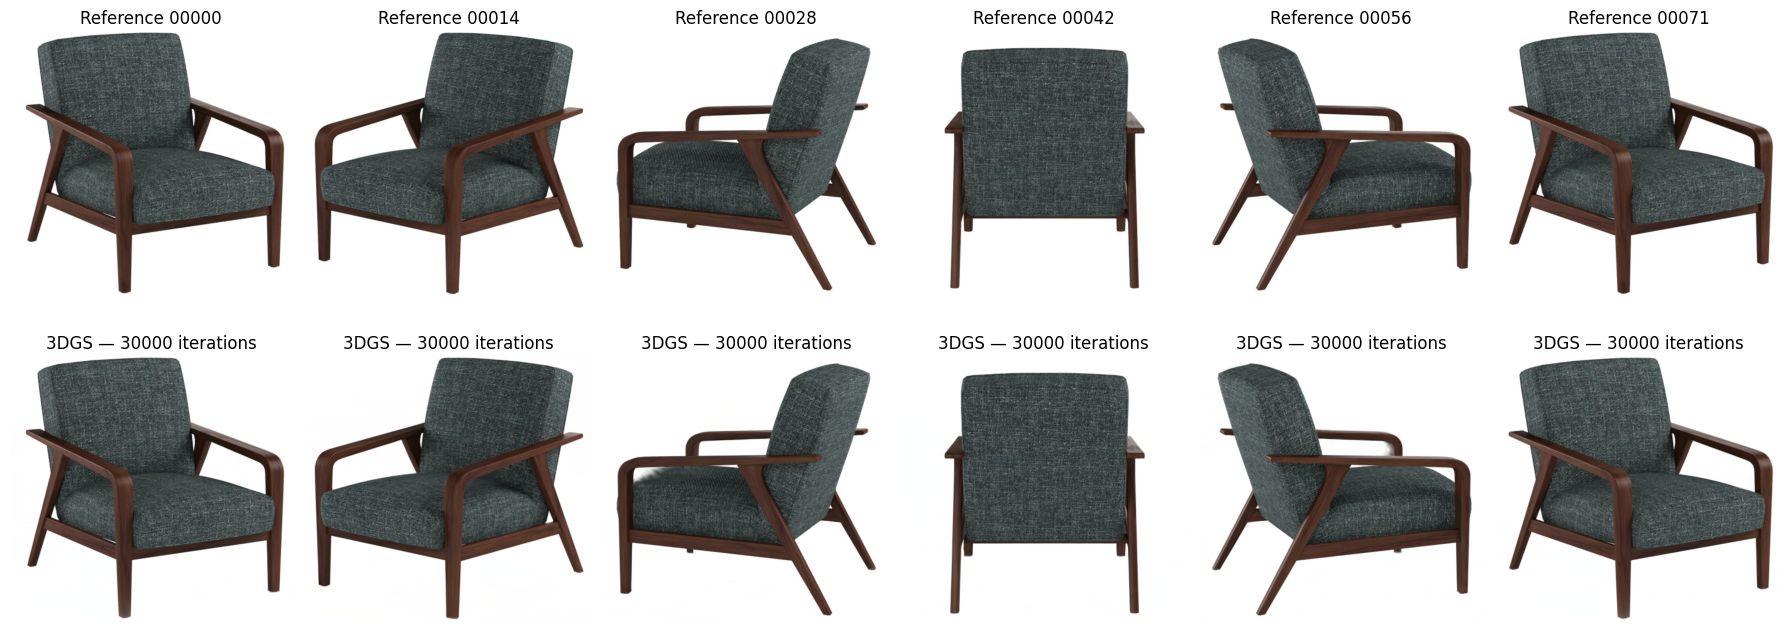

In [12]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# locate the rendered images and matching reference images
render_folder = baseline_folder / "train/ours_30000/renders"
reference_folder = baseline_folder / "train/ours_30000/gt"

render_paths = sorted(render_folder.glob("*.png"))

if not render_paths:
    raise RuntimeError("No rendered images were found.")

# sample views across the saved camera list
sample_indices = np.linspace(
    0, len(render_paths) - 1, 6, dtype=int
)

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for column, index in enumerate(sample_indices):
    render_path = render_paths[index]
    reference_path = reference_folder / render_path.name

    with Image.open(reference_path) as image:
        axes[0, column].imshow(image.convert("RGB"))

    with Image.open(render_path) as image:
        axes[1, column].imshow(image.convert("RGB"))

    axes[0, column].set_title(f"Reference {render_path.stem}")
    axes[1, column].set_title("3DGS — 30000 iterations")

    axes[0, column].axis("off")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

## Saving the Baseline Results

In [15]:
from IPython.display import FileLink, display
import shutil

# save the trained model, checkpoints, renders, and experiment settings
archive_path = shutil.make_archive(
    str(baseline_folder.parent / f"{baseline_folder.name}_results"),
    "zip",
    root_dir=baseline_folder.parent,
    base_dir=baseline_folder.name,
)

print("Results archive:", archive_path)
display(FileLink(archive_path))

Results archive: /kaggle/working/3dgs_runs/d3e97083_72views_30000_halfres_results.zip


/kaggle/working/3dgs_runs/d3e97083_72views_30000_halfres_results.zip